<a href="https://colab.research.google.com/github/ulugbek-lab/computer_vision/blob/main/menu_detector_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [78]:
print("Menu detector!")

Menu detector!


In [79]:
# ------------------------------
# Import Libraries
# ------------------------------
from google.colab import drive
import torchvision.transforms as transforms
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image, UnidentifiedImageError
from torch.utils.data import Dataset, DataLoader
import os
import numpy as np

from torchvision.models import mobilenet_v2

In [80]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [81]:
# Define Dataset Path

DATASET_PATH = '/content/drive/MyDrive/food101_dataset'
print(DATASET_PATH)



CUSTOM_CLASS_MAPPING = {
    'hamburger': 'hamburger',
    'hot dog': 'hot-dog',
    'chocolate_cake': 'dessert',  # label grouping | class consolidation(such as dessert)
    'cheesecake': 'dessert',      # label grouping | class consolidation(such as dessert)
    'kebab': 'kebab',
    'sushi': 'sushi'
}




CLASSES = ['hamburger', 'hot-dog', 'dessert', 'kebab', 'sushi']
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)} #assign number to classes
NUM_CLASSES = len(CLASSES)
print(CLASS_TO_IDX)
print(NUM_CLASSES) # 5 categories/classes


transform = transforms.Compose([
    transforms.Resize((224,224)), # resize image width & hight
    transforms.ToTensor(), # convert image to tensor; # H, W, C  => C, H, W(tensor transform)
    transforms.Normalize(mean=[0.485, 0.456,0.406],# pixel = (pixel - mean) /std
                         std=[0.229, 0.224, 0.225])
])




/content/drive/MyDrive/food101_dataset
{'hamburger': 0, 'hot-dog': 1, 'dessert': 2, 'kebab': 3, 'sushi': 4}
5


In [82]:


# ------------------------------
# Custom Dataset class
# ------------------------------


#( Step 1). Define only
class FoodDataset(Dataset):
  # (Step 4). Initialize the methods
  def __init__(self, images, labels, transform=None):
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    # print('images_length', len(self.images))
    return len(self.images)
  # (Step 6) Actual image is called
  def __getitem__(self, idx):
    img_path = self.images[idx]
    # print('img_path',img_path)
    label = self.labels[idx]
    # print('label',label)
  # (Step 7) Try to open the image!
    try:
        image = Image.open(img_path)
        if image.mode == "P" or image.mode == "RGBA":
          image = image.convert("RGBA").convert("RGB")
        else:
          image = image.convert("RGB")
    except (UnidentifiedImageError, OSError):
      print(f"Skipping broken image: {img_path}")
      return self.__getitem__((idx + 1) % len(self.images))# skip error image path
    if self.transform:
      image = self.transform(image)
  # ( Step 8) return
    return image, label
#


In [83]:
# ------------------------------
# Gather and Split class
# ------------------------------

# (Step 2). Start Mapping
all_images = [] # to store tuples
for original_class, mapped_class in CUSTOM_CLASS_MAPPING.items():
   class_path = os.path.join(DATASET_PATH, original_class) #/content/drive/MyDrive/food101_dataset/hamburger
   print('Class_path:', class_path)
   if not os.path.exists(class_path):
     print(f"Warning: {class_path} not found")
     continue
   for img in os.listdir(class_path):
     if img.endswith(('.jpg', '.jpeg', '.png')):
      full_path = os.path.join(class_path, img)#/content/drive/MyDrive/food101_dataset/hamburger.jpeg
      all_images.append((full_path, CLASS_TO_IDX[mapped_class]))

np.random.shuffle(all_images) # mix all the images
split = int(0.8 * len(all_images))
train_data = all_images[:split] # 1000 | 800 train_data | 200 val_data
val_data = all_images[split:]

train_images, train_labels = zip(*train_data)
val_images, val_labels = zip(*val_data)


# print('all_images', all_images)

#(Step 3). Call the class methods
dataset = FoodDataset(train_images, train_labels)
print(len(dataset))
# (Step 5). Ask for an actual image
img, lbl = dataset[7]






Class_path: /content/drive/MyDrive/food101_dataset/hamburger
Class_path: /content/drive/MyDrive/food101_dataset/hot dog
Class_path: /content/drive/MyDrive/food101_dataset/chocolate_cake
Class_path: /content/drive/MyDrive/food101_dataset/cheesecake
Class_path: /content/drive/MyDrive/food101_dataset/kebab
Class_path: /content/drive/MyDrive/food101_dataset/sushi
1920


In [84]:
train_dataset = FoodDataset(train_images, train_labels, transform=transform)
val_dataset = FoodDataset(val_images, val_labels, transform=transform)

In [85]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
# batch_size = 32 images right away sent;
# shuffle => mix;
# 2 workers loading in background for speed;  worker 1 → loads/prepares images and also worker 2 → loads/prepares images
# so training step receives =>  images:[32, 3, 224, 224] labels:32
# A DataLoader is basically a delivery system for your dataset.



In [86]:
 # Pretrained model

 model = mobilenet_v2(weights="IMAGENET1K_V1") # lighweight and CNN and pre trained model; 1000 categories; is a (Convolutional Neural Network)
 model.classifier[1] = nn.Linear(model.classifier[1].in_features, NUM_CLASSES) # fine-tuning | backbone(model brain) | model layer freeze
  # (1280)in_features in mobilenet_v2 => Those 1280 numbers are not 1280 classes. They are features the pretrained CNN extracted from the image before.
  # nn.Linear(1280, 5) contains weights connecting every one of those 1280 features to each of the 5 outputs.

 # ********    Pre-trained model => Fine-tuning(Training Data) => Fine-tuned Model    **************#

In [87]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)

device: cuda


In [88]:
criterion = nn.CrossEntropyLoss()# Loss Function | "70%" burger, "30%" sushi
optimizer = optim.Adam(model.parameters(), lr=0.001) # weight | Optimizer => Updates gradients (w, b); lr = learning rate
# Adam automatically adapts update sizes,  and is commonly convenient for neural networks
torch.backends.cudnn.benchmark = True # Benchmark Setting | Trick | 10-20% speed up training


In [89]:
# ------------------------------
# Training Loop
# ------------------------------

NUM_EPOCH = 10          # number of loops
best_accuracy = 0.0     # to save best result later

for epoch in range(NUM_EPOCH):
  model.train() # This puts MobileNet into training mode.
  running_loss = 0.0 # 70% | 30%loss = 100 %
  for images, labels in train_loader: #Forward and Backward (Backpropogation)
    images, labels = images.to(device), labels.to(device) # Secure
    optimizer.zero_grad() # zero the gradient to prevent number getting big
    outputs = model(images) # Forward Pass it to CNN model(MobileNetV2)
    loss = criterion(outputs, labels) # Calculate loss
    loss.backward()
    optimizer.step() # Adam optimizer
    running_loss += loss.item() # Track Loss

  #Validation
  model.eval()
  correct = 0
  total = 0
  with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

  val_acc = 100 * correct / total # Calculate Validation Accuracy
  print(f"Epoch[{epoch+1}/{NUM_EPOCH}] Loss:{running_loss/len(train_loader):.4f}, Val Accuracy: {val_acc:.2f}%")

  if val_acc > best_accuracy:
      best_accuracy = val_acc
      torch.save(model.state_dict(), '/content/menu_detector.pth')
      print("Saved new best model!")



Epoch[1/10] Loss:0.4011, Val Accuracy: 88.77%
Saved new best model!
Epoch[2/10] Loss:0.1874, Val Accuracy: 92.72%
Saved new best model!
Epoch[3/10] Loss:0.1625, Val Accuracy: 90.85%
Epoch[4/10] Loss:0.1525, Val Accuracy: 91.68%
Epoch[5/10] Loss:0.0759, Val Accuracy: 88.15%
Epoch[6/10] Loss:0.1130, Val Accuracy: 91.27%
Epoch[7/10] Loss:0.1806, Val Accuracy: 92.31%
Epoch[8/10] Loss:0.0737, Val Accuracy: 92.93%
Saved new best model!
Epoch[9/10] Loss:0.0739, Val Accuracy: 92.52%
Epoch[10/10] Loss:0.0473, Val Accuracy: 92.10%


# **Menu Detector Model Usage**

device: cuda
Upload one or more images of the food


Saving 36641.jpg to 36641.jpg


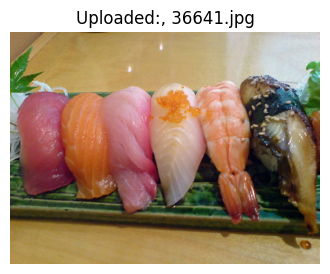

Prediction:
✅ hamburger: 99.33%
✅ dessert: 0.41%
✅ kebab: 0.18%
✅ sushi: 0.08%


In [95]:
# ------------------------------
# Required Imports
# ------------------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt


# ------------------------------
# Define Semantic Classes
# ------------------------------

CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'sushi'] # must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# ------------------------------
# Transform for uploaded Images( no augmentations! )
# ------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# ------------------------------
# Load Model
# ------------------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# ------------------------------
# Upload & Predict
# ------------------------------
print('Upload one or more images of the food')
uploaded = files.upload()

for image_name in uploaded.keys():
  image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

  # Display Image
  plt.figure(figsize=(4, 4))
  plt.imshow(image)
  plt.axis('off')
  plt.title(f'Uploaded:, {image_name}')
  plt.show()

  # Predict
  image_tensor = transform(image).unsqueeze(0).to(device)
  with torch.no_grad():
      output = model(image_tensor)
      probs = torch.softmax(output, dim=1)[0]
      topk = torch.topk(probs, 4)

  print("Prediction:")
  for i in range(topk.indices.size(0)):
      label = CLASSES[topk.indices[i]]
      confidence = topk.values[i].item() * 100
      print(f"✅ {label}: {confidence:.2f}%")

